# Weekly demand forecasting: analysis

This notebook tells the story; the work happens in `src/demand` and is run by `make all`. It reads the saved backtest (`results/forecasts.csv`, `results/metrics.json`) and recomputes the key numbers with the package's own functions.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, display
from demand import evaluate as ev
from demand.config import load_config
from demand.models import POINT_MODELS
cfg = load_config(ROOT / 'config.yaml')
m = json.loads((ROOT / 'results/metrics.json').read_text())
fc = pd.read_csv(ROOT / 'results/forecasts.csv', parse_dates=['week', 'cutoff'], dtype={'sku': str})
fc.head()

,sku,horizon,week,cutoff,actual,naive,seasonal_naive,ets,ets_lo,ets_hi,theta,theta_lo,theta_hi,gbm_lo,gbm,gbm_hi,is_total
0,15056N,1,2011-08-01,2011-07-25,102.0,25.0,98.0,84.661253,0.0,221.690348,123.034388,0.0,269.219393,17.157579,109.066007,215.149680,False
1,15056N,1,2011-08-08,2011-08-01,37.0,102.0,111.0,84.879690,0.0,221.130530,112.520030,0.0,258.002444,24.600440,78.597549,230.980173,False
2,15056N,1,2011-08-15,2011-08-08,138.0,37.0,157.0,85.131234,0.0,220.552152,75.710125,0.0,220.414761,19.932410,120.708193,232.552276,False
3,15056N,1,2011-08-22,2011-08-15,146.0,138.0,202.0,85.792298,0.0,220.632734,105.207759,0.0,249.433813,19.659292,87.557504,220.009195,False
4,15056N,1,2011-08-29,2011-08-22,25.0,146.0,57.0,85.686255,0.0,220.225684,124.304200,0.0,268.180146,35.010278,110.433212,206.006283,False


## 1. The series

20 top products plus the all-products total, 104 full weeks. The backtest targets are the last 18 weeks; the last 10 are the headline window.

In [2]:
panel = pd.read_parquet(ROOT / cfg['data']['panel'])
print(panel.groupby('sku')['units'].agg(['mean', 'std', lambda s: (s == 0).mean()]).rename(columns={'<lambda_0>': 'zero_share'}).round(1).head(8))
print(m['setup'])

         mean    std  zero_share
sku                             
15056N   94.2  108.5         0.0
20685    74.9   82.3         0.0
20725   304.5  145.2         0.0
21137   159.8  193.8         0.1
21621    64.5   72.8         0.0
21843    45.1   47.3         0.0
21931   257.5  125.8         0.0
22112    94.5  127.0         0.0
{'horizons': [1, 4], 'headline_weeks': 10, 'calibration_weeks': 8, 'headline_start': '2011-09-26', 'headline_end': '2011-11-28', 'calibration_start': '2011-08-01', 'peak_start': '2011-10-17', 'n_boot': 1000, 'nominal_coverage': 0.8, 'fits_per_series': 36}


## 2. Accuracy with bootstrap intervals

Pooled WAPE across products, 1 and 4 weeks ahead, recomputed from the forecasts.

1 week(s) ahead
                  wape           wape_ci      vs_baseline_ci    bias
naive           0.6319  [0.5229, 0.7954]          [0.0, 0.0] -0.0383
seasonal_naive  0.6508  [0.5079, 0.8693]   [-0.1048, 0.2012]  0.1349
ets             0.4588  [0.3966, 0.5395]  [-0.2585, -0.1033] -0.1783
theta           0.4794  [0.4108, 0.5691]  [-0.2303, -0.0996] -0.1401
gbm             0.5318  [0.4556, 0.6384]  [-0.1686, -0.0451] -0.0272
4 week(s) ahead
                  wape           wape_ci      vs_baseline_ci    bias
naive           0.6281    [0.54, 0.7629]          [0.0, 0.0]  -0.244
seasonal_naive  0.6508  [0.5079, 0.8693]   [-0.1016, 0.2084]  0.1349
ets             0.5212  [0.4369, 0.5942]  [-0.2195, -0.0053] -0.2618
theta           0.5236   [0.4455, 0.595]   [-0.209, -0.0173] -0.2443
gbm             0.5494   [0.457, 0.6595]   [-0.1737, 0.0081] -0.0669


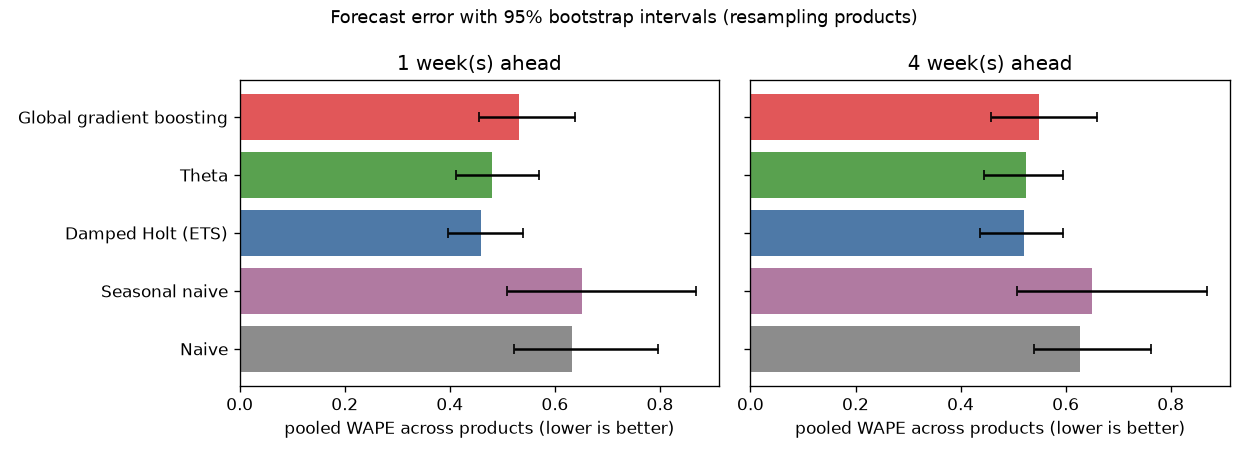

In [3]:
head = ev.headline_window(fc, m['setup']['headline_weeks'])
for h in [1, 4]:
    prod = head[(head['horizon'] == h) & ~head['is_total']]
    res = ev.bootstrap_products(prod, POINT_MODELS, 'naive', 1000, 42)
    print(f'{h} week(s) ahead')
    print(pd.DataFrame(res).T[['wape', 'wape_ci', 'vs_baseline_ci', 'bias']])
display(Image(str(ROOT / 'results/wape_by_model.png')))

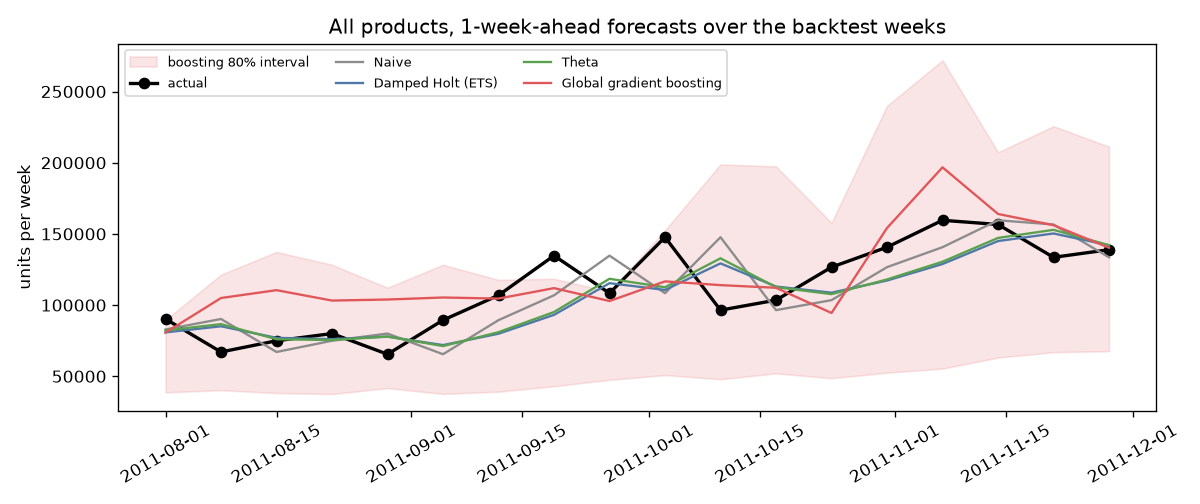

In [4]:
display(Image(str(ROOT / 'results/backtest_total.png')))

## 3. Prediction intervals

        coverage     coverage_ci relative_width
1 ets      0.825  [0.7649, 0.88]          1.323
  theta    0.815  [0.745, 0.875]          1.318
  gbm       0.75  [0.68, 0.8151]          1.277
4 ets       0.91  [0.85, 0.9601]          2.118
  theta     0.95   [0.915, 0.98]          2.433
  gbm      0.745   [0.665, 0.82]          1.305


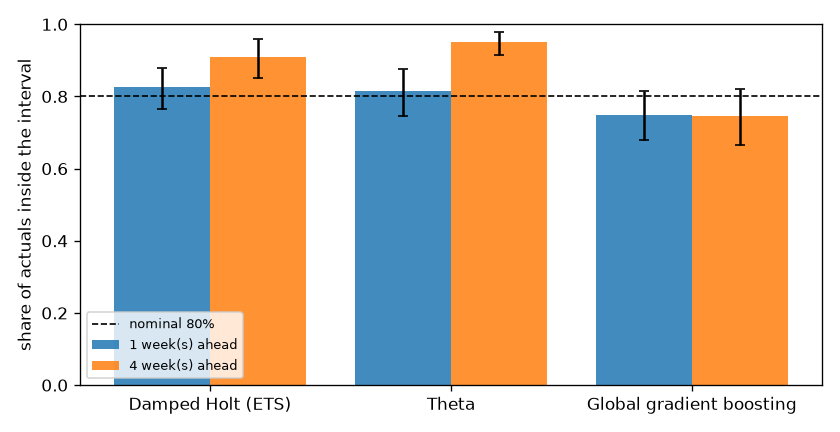

In [5]:
print(pd.DataFrame({(h, k): v for h, d in m['intervals'].items() for k, v in d.items()}).T[['coverage', 'coverage_ci', 'relative_width']])
display(Image(str(ROOT / 'results/interval_coverage.png')))

## 4. Where the error sits: volume tiers and the Christmas peak

segment_type  segment  products  weeks  actual_units  naive  seasonal_naive   ets  theta   gbm
        tier      low         7     10        8038.0  0.703           0.775 0.592  0.569 0.596
        tier      mid         7     10       19641.0  0.715           0.628 0.486  0.507 0.572
        tier     high         6     10       58398.0  0.594           0.641 0.431  0.458 0.510
      period pre-peak        20      3       22351.0  0.797           0.858 0.503  0.523 0.644
      period     peak        20      7       63726.0  0.574           0.578 0.443  0.464 0.493


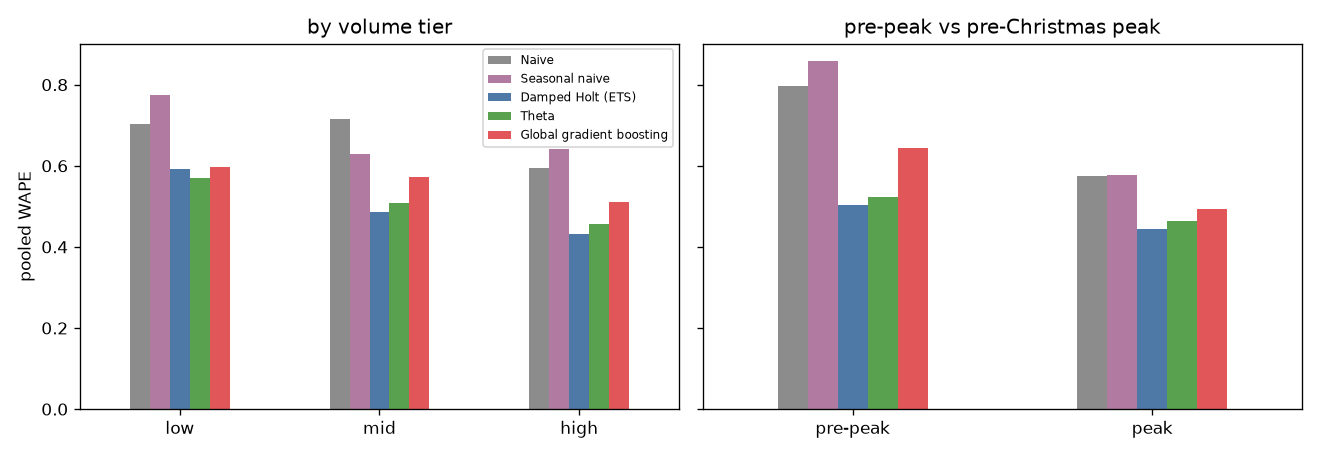

In [6]:
print(pd.read_csv(ROOT / 'results/segment_errors.csv').round(3).to_string(index=False))
display(Image(str(ROOT / 'results/segment_errors.png')))

In [7]:
per = pd.read_csv(ROOT / 'results/product_errors.csv', dtype={'sku': str})
per[per['model'] == m['best_model_h1']].sort_values('wape', ascending=False).head(8).round(2)

,sku,model,wape,wape_lo,wape_hi,mae,bias,description
2,15056N,ets,1.27,0.61,2.83,50.97,1.08,EDWARDIAN PARASOL NATURAL
67,48138,ets,0.98,0.65,1.80,50.00,0.54,DOORMAT UNION FLAG
92,85099F,ets,0.75,0.45,1.34,236.46,0.14,JUMBO BAG STRAWBERRY
27,21843,ets,0.74,0.43,0.91,34.52,-0.57,RED RETROSPOT CAKE STAND
42,22178,ets,0.69,0.50,0.96,372.71,-0.12,VICTORIAN GLASS HANGING T-LIGHT
22,21621,ets,0.69,0.36,1.15,17.14,0.69,VINTAGE UNION JACK BUNTING
17,21137,ets,0.62,0.43,0.79,189.79,-0.35,BLACK RECORD COVER FRAME
72,79321,ets,0.55,0.38,0.67,176.74,-0.35,CHILLI LIGHTS


## 5. Inventory view

Safety stock from each model's calibration-week RMSE; fill rate and leftover stock in the headline weeks.

         model  target_service  fill_rate  weeks_short  safety_stock_per_week  leftover_per_week
         naive            0.90      0.865        0.190               6968.506           7804.843
         naive            0.95      0.892        0.150               8943.981           9547.074
         naive            0.98      0.919        0.140              11167.371          11538.199
seasonal_naive            0.90      0.930        0.115               7828.825           9591.859
seasonal_naive            0.95      0.952        0.070              10048.188          11618.782
seasonal_naive            0.98      0.968        0.060              12546.074          13979.836
           ets            0.90      0.849        0.170               5748.179           5514.548
           ets            0.95      0.876        0.145               7377.708           6911.744
           ets            0.98      0.901        0.125               9211.738           8525.444
         theta            0.90

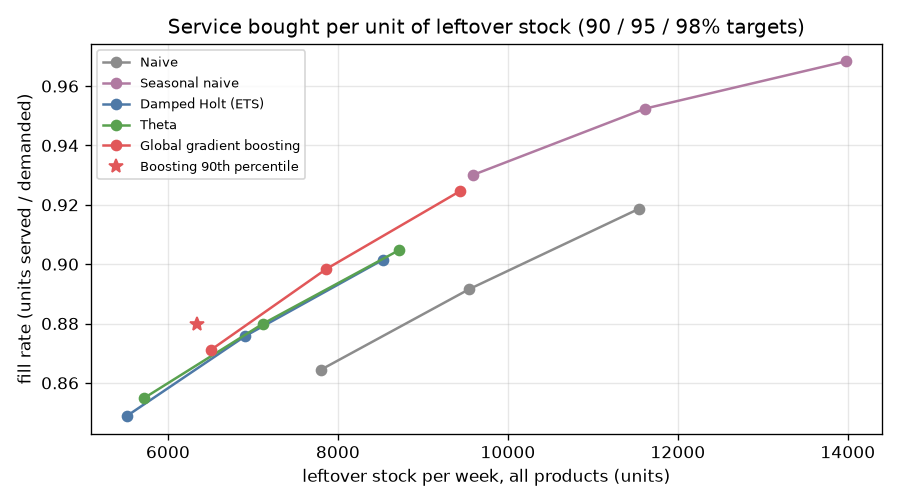

In [8]:
print(pd.read_csv(ROOT / 'results/inventory.csv').round(3).to_string(index=False))
display(Image(str(ROOT / 'results/inventory_tradeoff.png')))

## 6. Sensitivity to the backtest window

In [9]:
pd.read_csv(ROOT / 'results/window_sensitivity.csv').round(3)

,weeks,naive,seasonal_naive,ets,theta,gbm
0,6,0.576,0.557,0.435,0.453,0.463
1,10,0.632,0.651,0.459,0.479,0.532
2,18,0.614,0.649,0.466,0.479,0.507


## Takeaways

- Per-series damped Holt smoothing is the most accurate product forecast one and four weeks ahead; the gap to naive is well outside the bootstrap noise.
- The global boosting model is the least biased and is best on the total, where the holiday features matter.
- Safety stock sized on pre-peak errors falls short of its service target in the peak: size it on peak-season errors.